## 딥러닝 2 정리

### 목차
1. Attention과 Transformer 등장 배경
2. Self-Attention
3. Multi-Head Attention
4. Transformer 전체 구조

---

### 1. Attention과 Transformer 등장 배경

#### 1-1. Attention의 등장

- **Seq2Seq의 문제**
    - 입력이 길든 짧든 같은 크기의 Context Vector에 다 넣어야 함 → 길수록 정보 손실
    - 디코더는 단어가 달라도 같은 요약본 참고
    - Context Vector는 마지막 hidden state라 앞쪽 단어는 점점 희미해짐

- **Attention**
: 현재 단어와 관련 있는 부분에 더 높은 가중치를 주는 방법
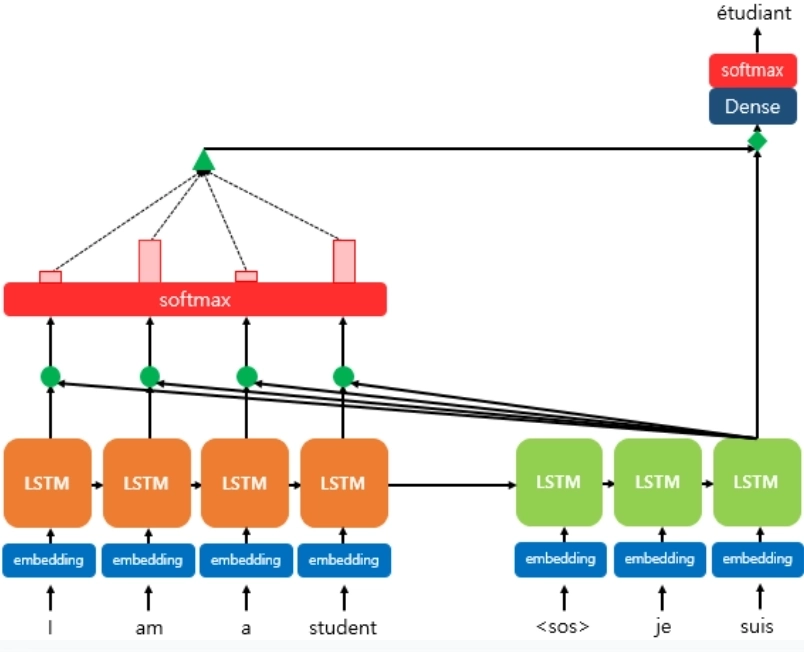
    - 단어 생성 시 입력 문장 전체를 다시 봄
    - 출력 단어마다 Context Vector 새로 생성
    - 인코더: 모든 hidden state 생성 후 유지
    - 디코더: 현재 상태 = 다음 단어 예측 시점
    - 디코더와 인코더의 모든 위치를 비교해 관련도 점수 계산 (병렬화 가능성!)
    - softmax: 계산된 점수 → 어텐션 가중치로 변환

- **Attention 과정**
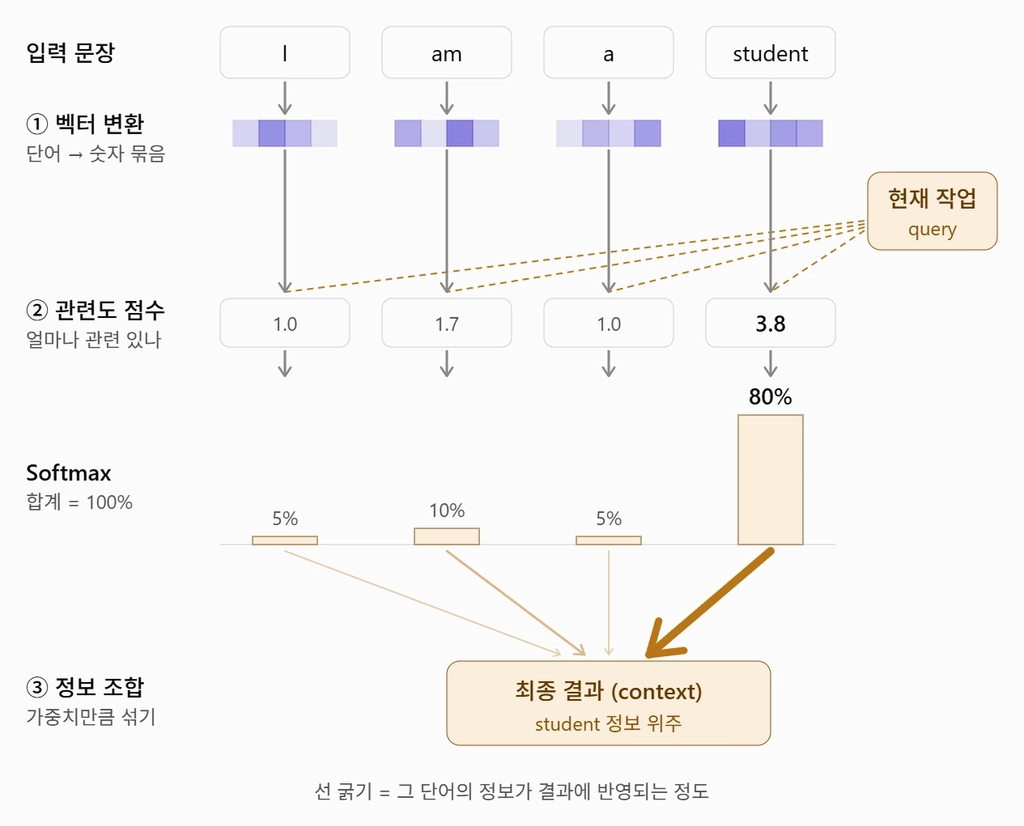
    1. 입력 단어 벡터로 변환
    2. 관련도 점수 계산 (현재 - 입력 단어 사이)
    3. Softmax로 확률 값으로 변환 → **Attention Weight**
    4. 비율만큼 hidden state 섞어 **Context Vector** 생성

- 장점
    - **시간 유연성** (vs RNN): 거리와 상관없이 모든 단어 직접 비교 → 장기 의존성 문제 x
    - **공간 유연성** (vs CNN): 모든 위치 연결해 전체 관계 학습 → 층 쌓지 않아도 됨
    - **병렬화** (vs RNN): 관련도 독립적으로 계산 가능

- 한계
    - LSTM 위에서 돌기 때문에 모델 전체는 순서대로 처리
    - Attention은 RNN을 돕는 보조 역할

#### 1-2. Attention is All You Need

- `Attention is All You Need` 논문
    - Transformer 구조 처음 발표
    - RNN, CNN 제거 → Self-Attention으로 입력 - 출력 관계 계산 = Transformer 모델
    - 순환과 합성곱은 필수가 아니라는 걸 보여줌
    - 병렬화로 빠르게 학습 가능

- 영향
    - **LLM:** 디코더를 쌓은 GPT, 인코더를 쌓은 BERT 등장
    - **NLP:** 번역, 요약, 질의응답의 표준 구조
    - **다른 분야:** 이미지, 음성으로 확장

#### 1-3. Transformer란?

- **Transformer**
: Attention만으로 문장 전체를 한 번에 처리하는 인코더 - 디코더 모델
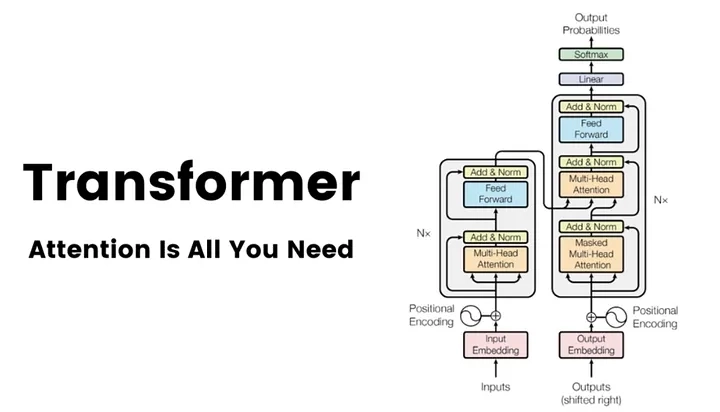
    - 구조
        - **인코더:** 입력 문장 이해
        - **디코더:** 출력 문장 생성
        - 같은 층을 N개 쌓아서 구성

| 구분 | Seq2Seq + Attention | Transformer |
| --- | --- | --- |
| 내부 | LSTM | Self-Attention |
| Attention 역할 | 보조 | 모델 그 자체 |
| 사용 위치 | 디코더 → 인코더 1곳 | 인코더, 디코더, 사이 3곳 |
| 순서 정보 | RNN이 읽으면서 반영 | Positional Encoding으로 추가 |
| 병렬 처리 | 불가 | 가능 |

- 핵심 기술
    - **Self-Attention:** 문장 안 단어끼리 관계 파악
    - **Multi-Head Attention:** 여러 관점으로 나눠서 관계 파악
    - **Positional Encoding:** 사라진 순서 정보 보완

---

### 2. Self-Attention

#### 2-1. Query, Key, Value

- **Attention 계산**
: Query와 Key를 비교해 관련도를 구하고, 그 비율만큼 Value를 섞는 것
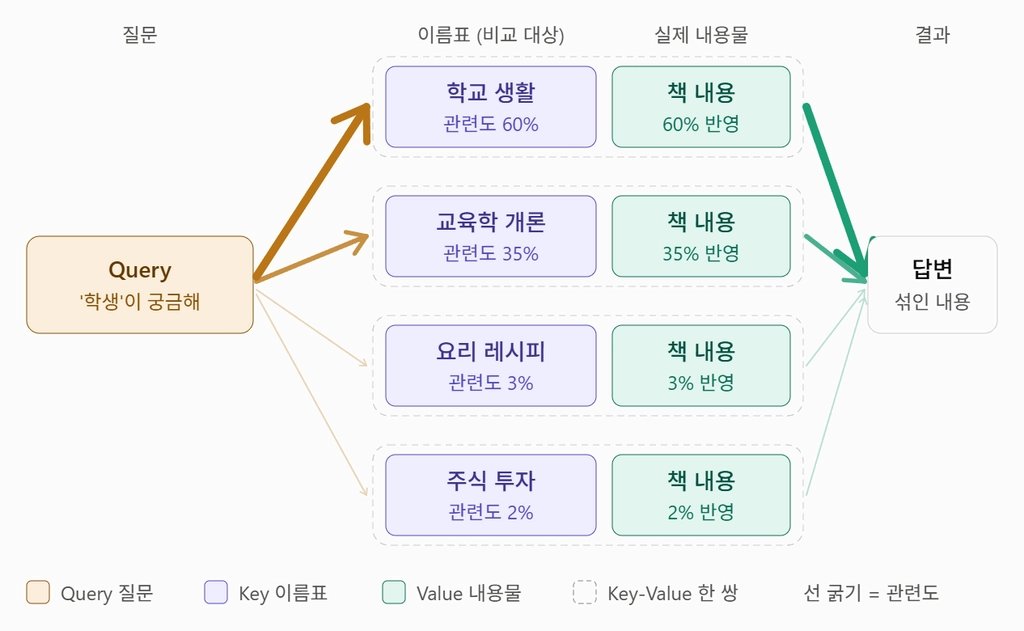
    - **Query:** 현재 단어의 질문
    - **Key:** 각 단어의 이름표 벡터
    - **Value:** 각 단어가 실제로 전달하는 정보

#### 2-2. Cross-Attention vs Self-Attention

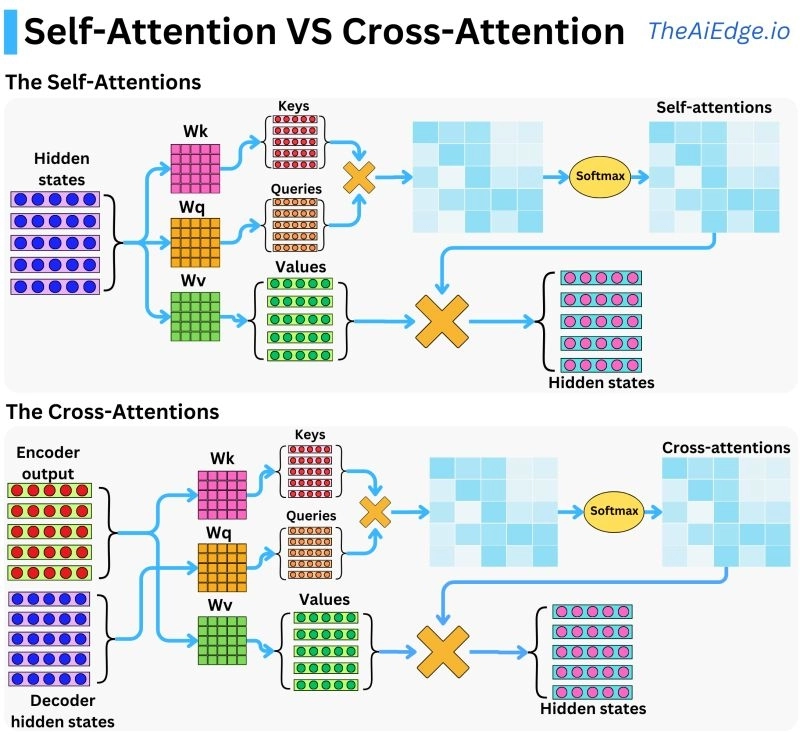

- **Cross-Attention**
: 디코더가 인코더를 참고해 다음 단어를 만들어 내는 구조
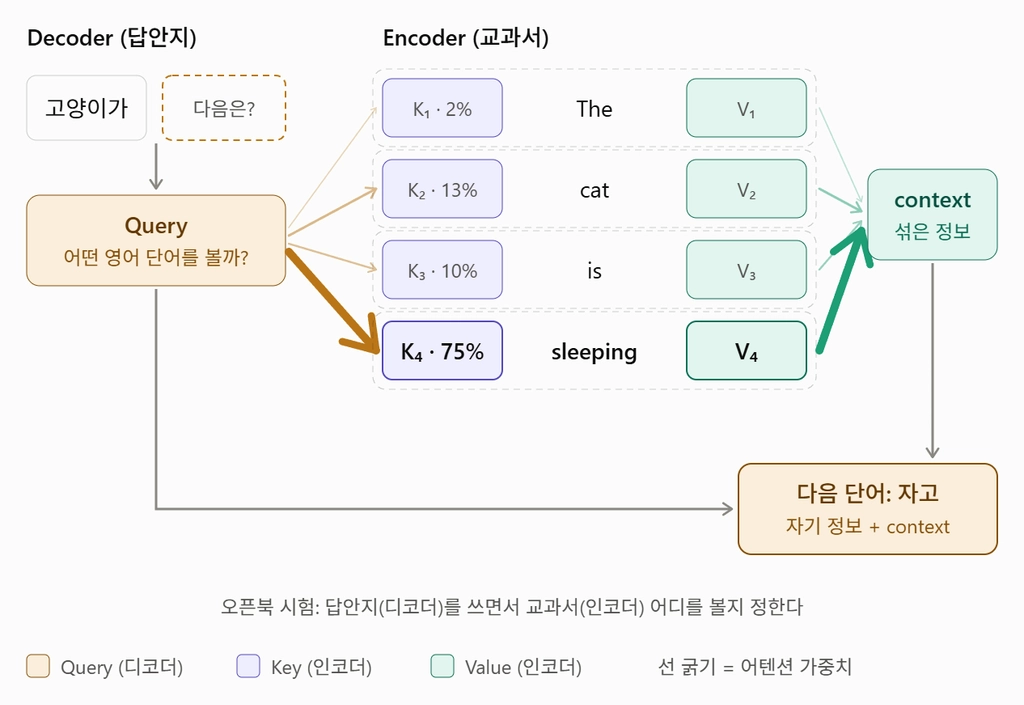
    1. 현재 상태 Query 생성
    2. 원문 단어들의 벡터를 Key, Value로 사용
    3. 관련도 계산 → softmax로 비율 변환
    4. 비율만큼 Value를 섞어 Context Vector 생성

- **Self-Attention**
: 같은 문장 안에서 Query와 Key를 동시에 비교하는 구조
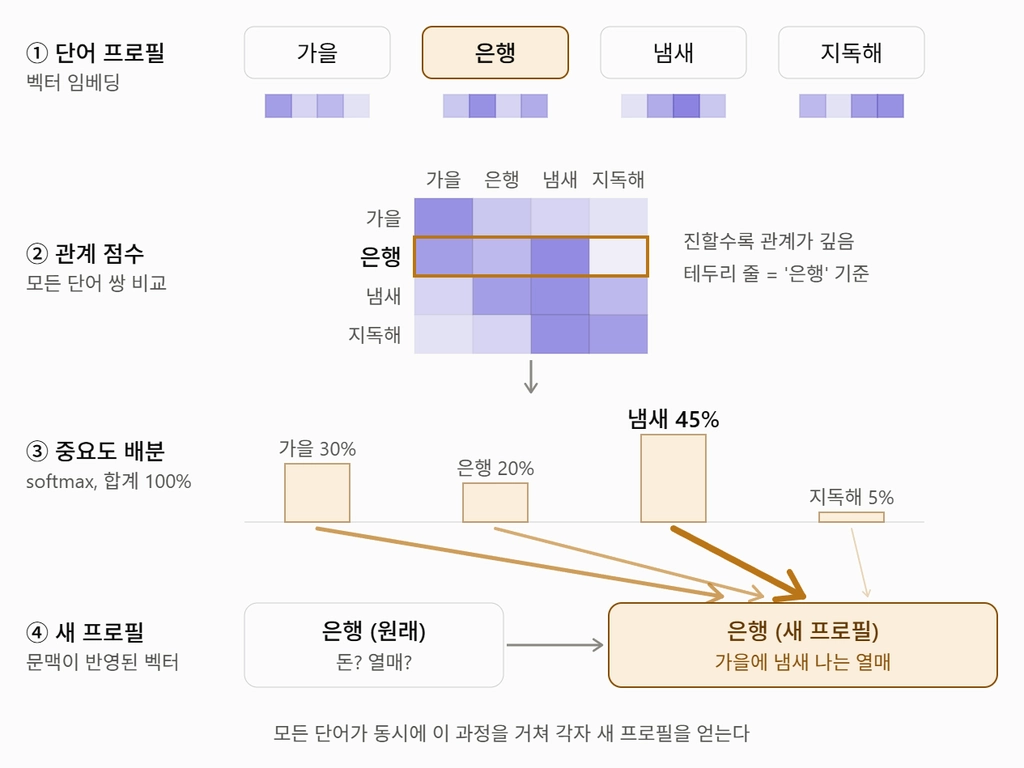
    1. 각 단어를 벡터로 바꾸고 Q, K, V 생성
    2. Query - Key를 비교해 관련도 점수 계산
    3. softmax와 어텐션 가중치로 중요도 판단
    4. 비율만큼 Value를 섞어 새 벡터 생성
    → 병렬 처리 가능!

| 구분 | Cross-Attention | Self-Attention |
| --- | --- | --- |
| 참조 대상 | 다른 시퀀스 (디코더 → 인코더) | 같은 시퀀스 (문장 내부) |
| 아키텍처 | RNN | Tranformer |
| 결과 | Context Vector | 문맥 반영된 새 벡터 |

- Transformer
    - **인코더:** Self-Attention → 원문 단어끼리 관계 파악
    - **디코더:** Self-Attention → 번역 중인 단어끼리 관계 파악 (뒤쪽 단어는 가림)
    - **인코더-디코더 사이:** Cross-Attention → 원문 참고

#### 2-3. Scaled Dot-Product Attention

- **Dot-Product Attention**
: Query와 Key를 내적해서 관련도 점수를 구하는 방법
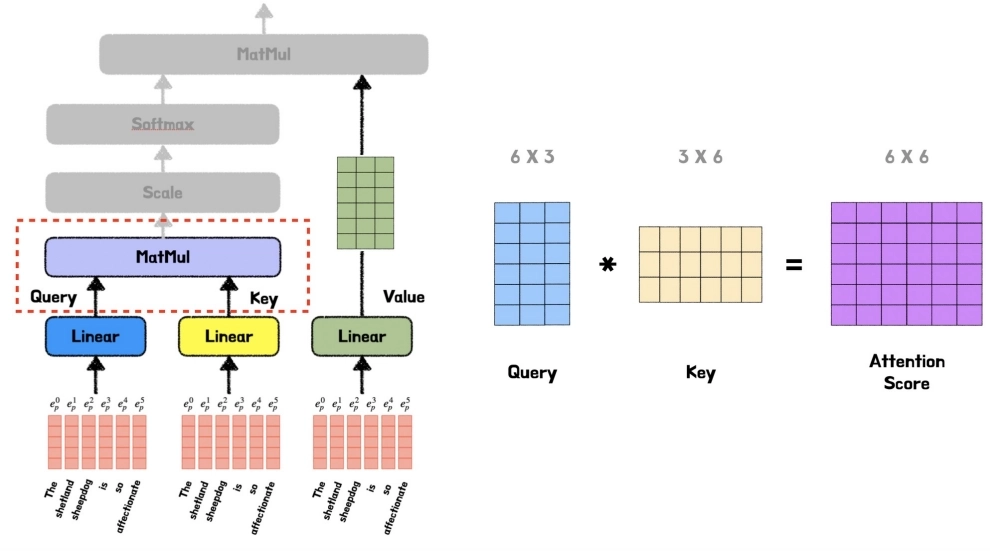
    - **내적:** 같은 위치끼리 곱해서 더한 값 (클수록 관련 높다)
    - 과정
        1. 관련도 점수 계산
        2. softmax → Attention Weight 산출 → V와 곱하기

- **문제**
    - 차원이 커지면 내적값 분산도 커져 점수들이 넓게 퍼진다
    - 큰 점수가 softmax에서 확률을 다 가져감
    - 기울기가 0에 가까워져 학습이 잘 안 됨

- **Scaled Dot-Product Attention**
: 내적값을 $\sqrt{d_k}$로 나눠서 크기를 맞추는 방법
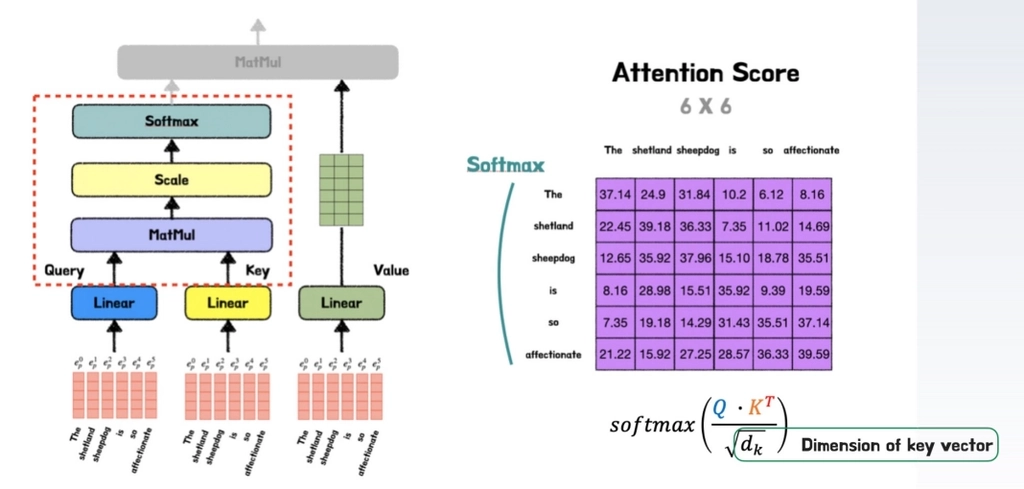
    - Q와 K를 내적해 나온 관련도 점수를 $\sqrt{d_k}$로 나눈다 → Softmax → Attention Weight 산출 → V와 곱하기
    - 차원이 커져도 점수가 안정적이다
    - $Attention(Q, K, V) = softmax(\dfrac{QK^T}{\sqrt{d_k}})V$

---

### 3. Multi-Head Attention

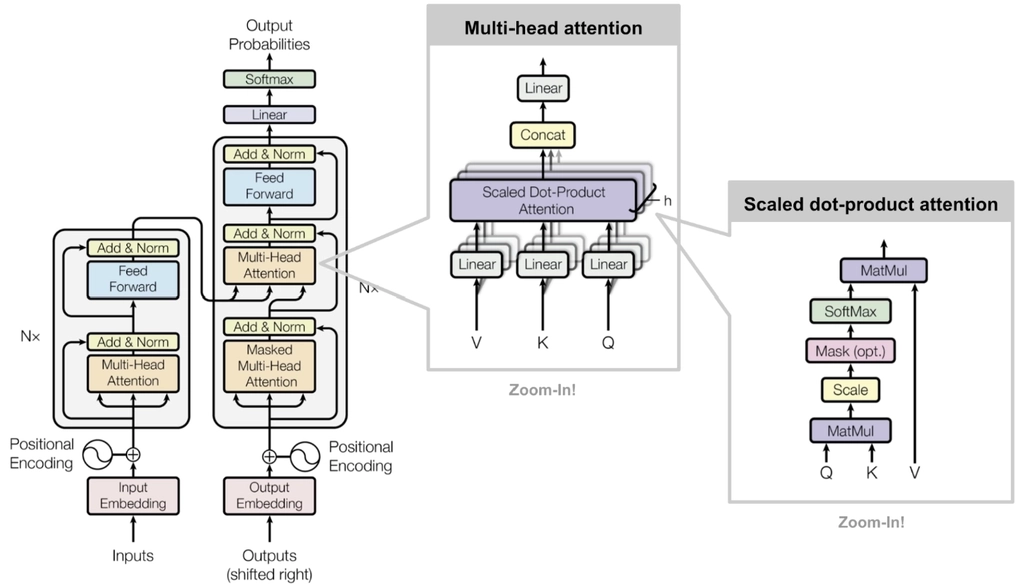

#### 3-1. Single-Head Attention VS Multi-Head Attention

- **헤드**
: Attention을 한 번 계산하는 단위
    - 헤드마다 $W^Q, W^K, W^V$가 달라서 집중하는 단어가 달라짐

- **Single-Head**
    - 헤드 1개, 가중치 합 1
    - 여러 관계가 필요할 시 정보가 섞여 흐려짐

- **Multi-Head**
    - 헤드마다 집중력 100%씩
    - 결과를 이어 붙여 정보 섞이지 x

#### 3-2. 작동 방식

- 단어 벡터 512차원, 헤드 8개, 헤드당 64차원
| 단계 | 하는 일 | 크기 변화 |
| --- | --- | --- |
| 분할 | 헤드별로 W 곱해 Q, K, V를 따로 만듦 | 512 → 64 × 8세트 |
| 병렬 계산 | 8개 헤드가 동시에 Attention 계산 | 64 × 8개 |
| 결합 | 8개 결과를 한 줄로 연결 | 64 × 8 → 512 |
| 최종 투영 | $W^O$를 곱해 8개 관점 합침 | 512 → 512 |

- **병렬 어텐션 계산** 
    1. 각 단어의 Q와 K를 내적
    2. $\sqrt{64} = 8$로 나눔
    3. Softmax로 비율 변환 (합 1)
    4. 비율대로 $V$ 섞음 → 64차원 결과

→ 이어 붙이고 헤드별 관점 하나로 합쳐서 최종 벡터 얻기

---

### 4. Transformer 전체 구조

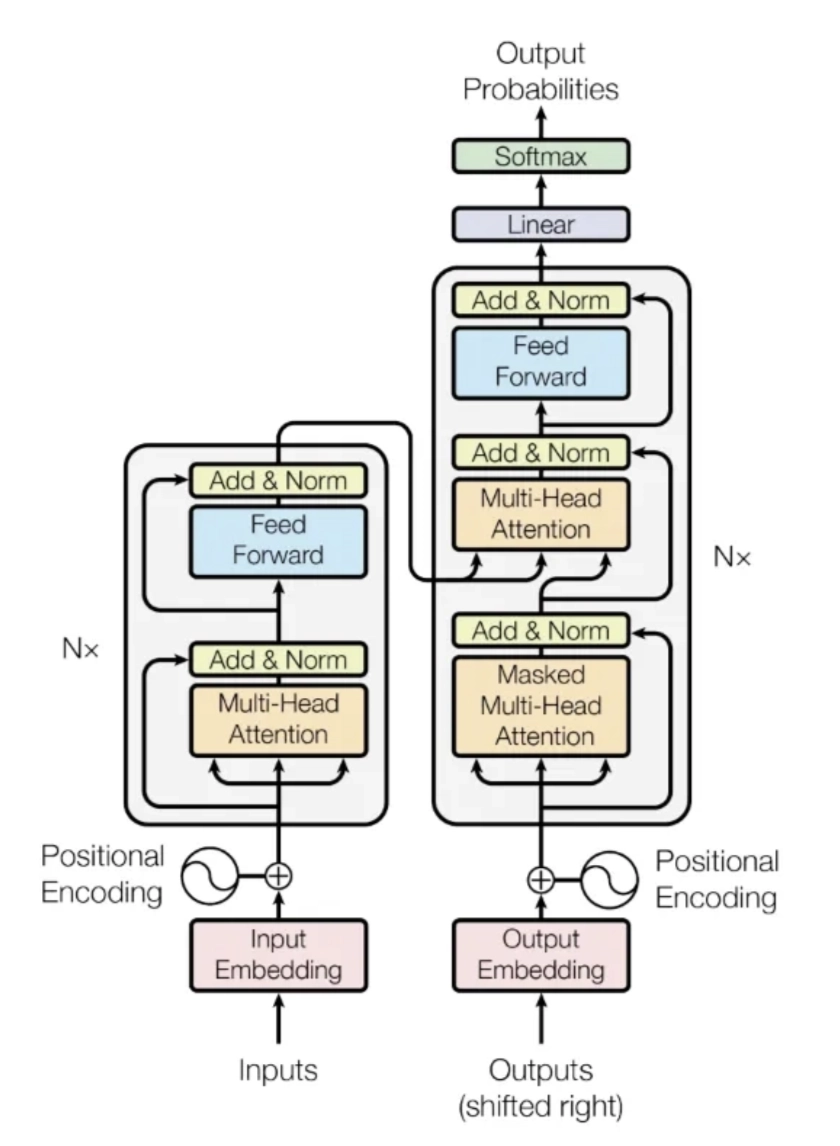

#### 4-1. 전처리

- **순서:** 입력 → 토큰화 → 임베딩 → Positional Encoding

- **토큰화**
: 문장을 모델이 다루는 기본 단위인 토큰으로 자르는 것
    - 단어 하나 = 토큰 하나 (길면 조각냄)
    - 문장 부호 → 토큰

- **임베딩**
: 토큰을 숫자 벡터로 바꾸는 것
    - 뜻이 비슷한 단어끼리 가깝게 위치
    - 무작위 배치 → 학습 → 맞는 자리에 배치됨 

- **Positional Encoding**
: 단어 순서 정보를 임베딩에 더하는 단계
    - 단어를 한 번에 보는 Transformer에게 순서를 알려 주는 역할
    - 벡터끼지 더함 (이어 붙이기 x)

#### 4-2. Encoder

- **Encoder**
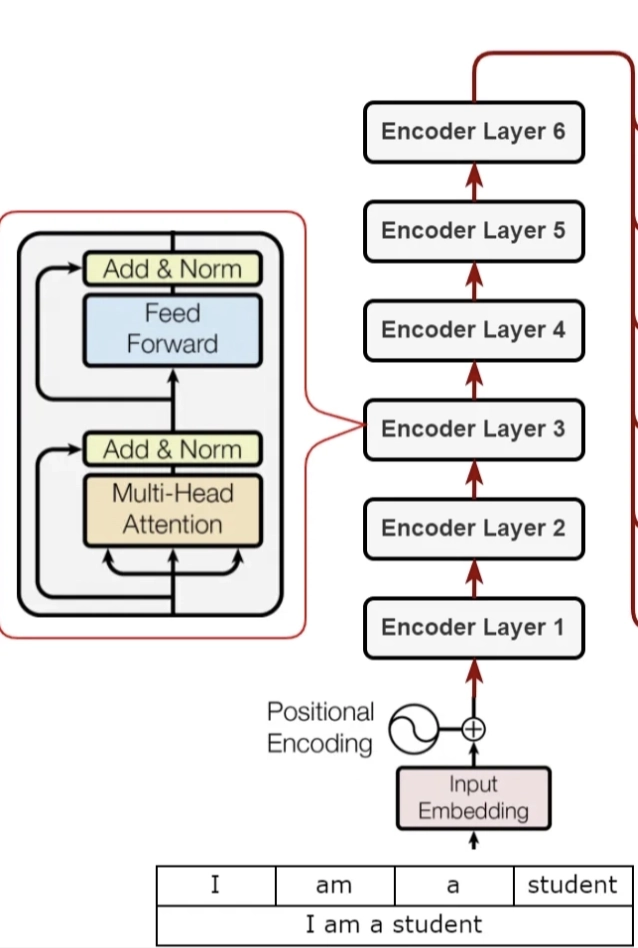
    - **Multi-Head Self-Attention:** 원문 단어끼리 문맥 파악
    - **Feed-Forward Network:** 단어를 하나씩 가공

- **Feed-Forward Network**
    - 512차원 → 2048차원 → 512차원으로 가는 신경망 (사이에 ReLU)
    - 단어마다 따로, 같은 신경망으로 (정보 교환 x)
    - $FFN(x) = max(0, xW_1 + b_1)W_2 + b_2$

- **Add & Norm**
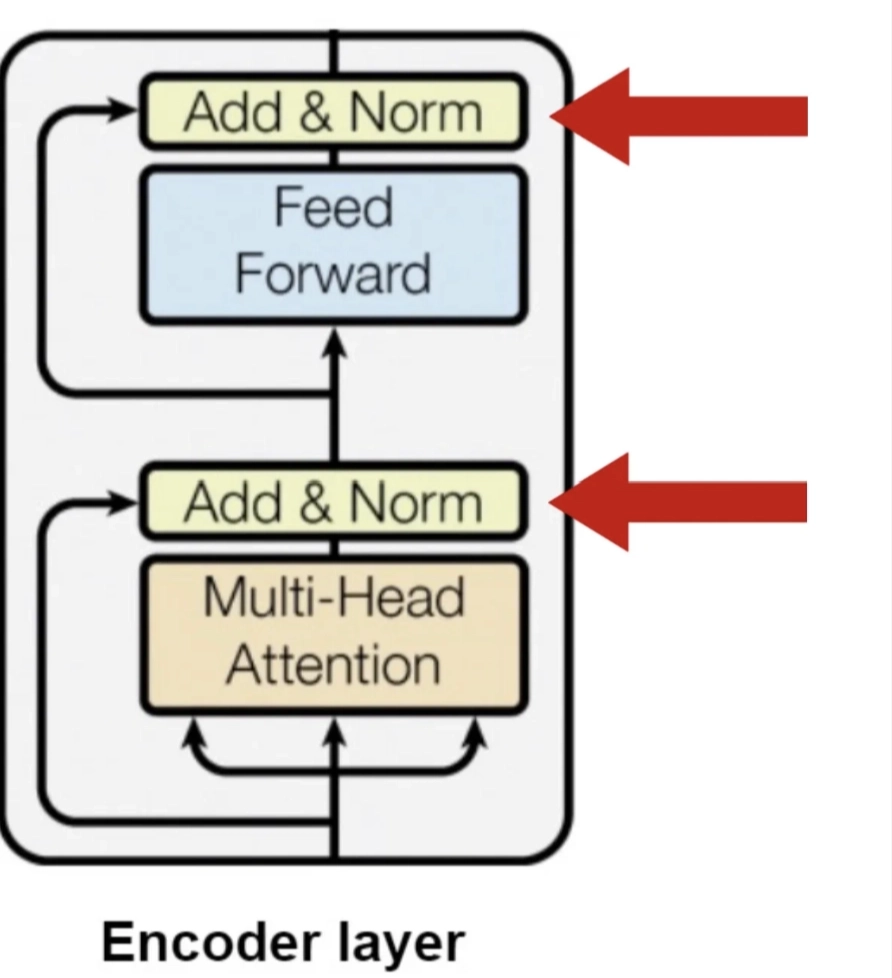
    - **Add:** 결과에 입력값을 더해 잔차 연결
    - **Norm:** 벡터 안 숫자 정규화 (평균 0, 분산 1로)

#### 4-3. Decoder

- **Decoder**
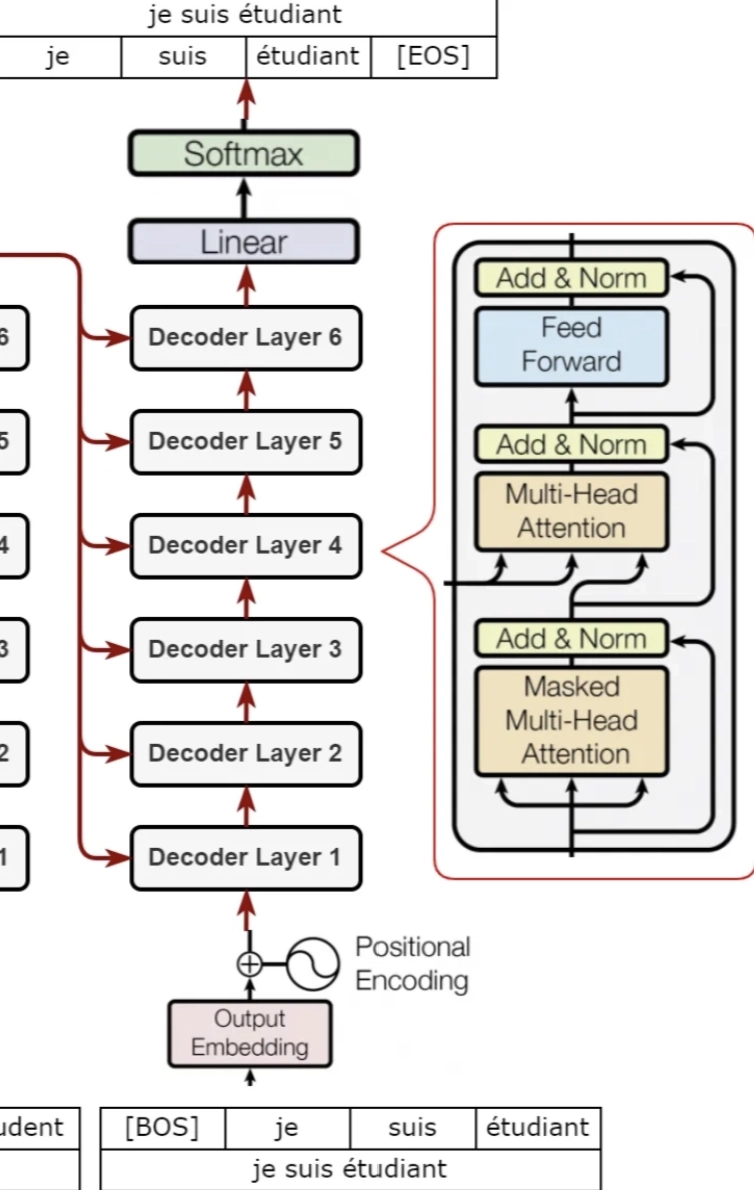
    - **Masked Multi-Head Self-Attention:** 쓴 단어끼리 관계 파악
    - **Cross-Attention:** Encoder 출력에서 필요한 부분 찾기
    - **Feed-Forward Network:** Encoder와 동일
    - 부품마다 Add & Norm이 붙음
    - 다 돌면 Linear + Softmax로 다음 단어 확률 계산

- **Masked Multi-Head Attention**
: 미래 단어를 가려서 앞 단어만 보게 하는 방법

- **Encoder-Decoder Attention**
: 입력 문장 - 출력 문장 연결하는 Cross-Attention
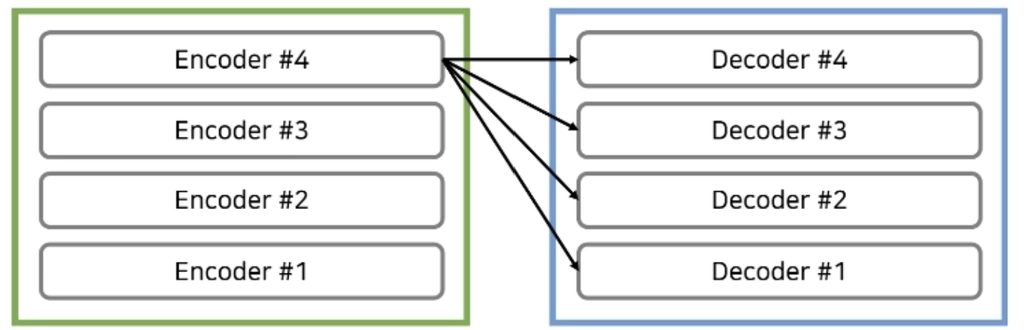
    - **Q:** Masked Self-Attention 지난 출력 (Decoder에서)
    - **K, V:** Encoder 마지막 층 출력 (Encoder에서)